In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUT = Path("images")
OUT.mkdir(exist_ok=True)
sns.set_theme(style="darkgrid")

raw = pd.read_csv("datasets/ramen-ratings.csv", encoding="utf-8")

In [2]:
print("Размер датасета:", raw.shape)
print(" ")
print("Поле - количество пропусков:\n",raw.isna().sum())
print(" ")
print("Кол-во дубликатов:", raw.duplicated().sum())

Размер датасета: (2580, 7)
 
Поле - количество пропусков:
 Review #       0
Brand          0
Variety        0
Style          2
Country        0
Stars          0
Top Ten     2539
dtype: int64
 
Кол-во дубликатов: 0


In [3]:
data = raw.copy()
for col in ["Brand", "Variety", "Country"]:
    data[col] = data[col].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
data["Style"] = data["Style"].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
data["Style"] = data["Style"].replace("", pd.NA)
data["Top Ten"] = data["Top Ten"].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
data["Top Ten"] = data["Top Ten"].replace("", pd.NA)
data["Stars"] = pd.to_numeric(data["Stars"], errors="coerce")
data["Review #"] = pd.to_numeric(data["Review #"], errors="coerce").astype("Int64")
before = len(data)
data = data.drop_duplicates().copy()
print(f"Удалено полных дубликатов: {before - len(data)}")
rating_min, rating_max = data["Stars"].min(), data["Stars"].max()
data["Stars_normalized_0_1"] = (data["Stars"] - rating_min) / (rating_max - rating_min)
display(data.isna().sum().to_frame("Пропуски после очистки"))
print("Итоговый размер:", data.shape)
data.to_csv("datasets/cleaned_ramen_ratings.csv", index=False, encoding="utf-8-sig")

Удалено полных дубликатов: 0


,Пропуски после очистки
Review #,0
Brand,0
Variety,0
Style,2
Country,0
Stars,3
Top Ten,2543
Stars_normalized_0_1,3


Итоговый размер: (2580, 8)


In [4]:
display(data["Stars"].describe().to_frame("Оценка"))
print("Стран:", data["Country"].nunique())
print("Брендов:", data["Brand"].nunique())
print("Уникальных разновидностей:", data["Variety"].nunique())
print("Средняя оценка:", round(data["Stars"].mean(), 3))
print("Медианная оценка:", round(data["Stars"].median(), 3))
print("Страна с наибольшим числом обзоров:", data["Country"].value_counts().idxmax())
print("Бренд с наибольшим числом обзоров:", data["Brand"].value_counts().idxmax())

,Оценка
count,2577.000000
mean,3.654676
std,1.015331
min,0.000000
25%,3.250000
50%,3.750000
75%,4.250000
max,5.000000


Стран: 38
Брендов: 355
Уникальных разновидностей: 2412
Средняя оценка: 3.655
Медианная оценка: 3.75
Страна с наибольшим числом обзоров: Japan
Бренд с наибольшим числом обзоров: Nissin


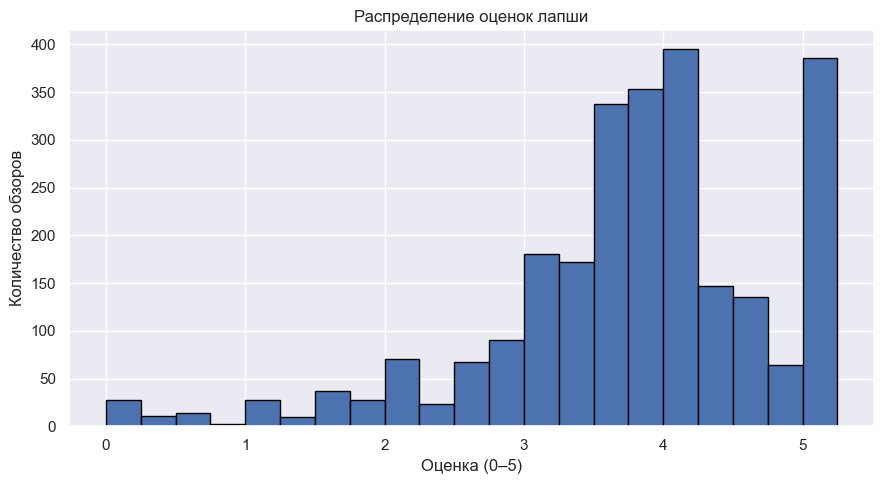

In [5]:
plt.figure(figsize=(9,5))
plt.hist(data["Stars"].dropna(), bins=np.arange(0, 5.26, .25), edgecolor="black")
plt.title("Распределение оценок лапши"); plt.xlabel("Оценка (0–5)"); plt.ylabel("Количество обзоров")
plt.tight_layout(); plt.savefig(OUT/"02_rating_distribution.png", dpi=160); plt.show()

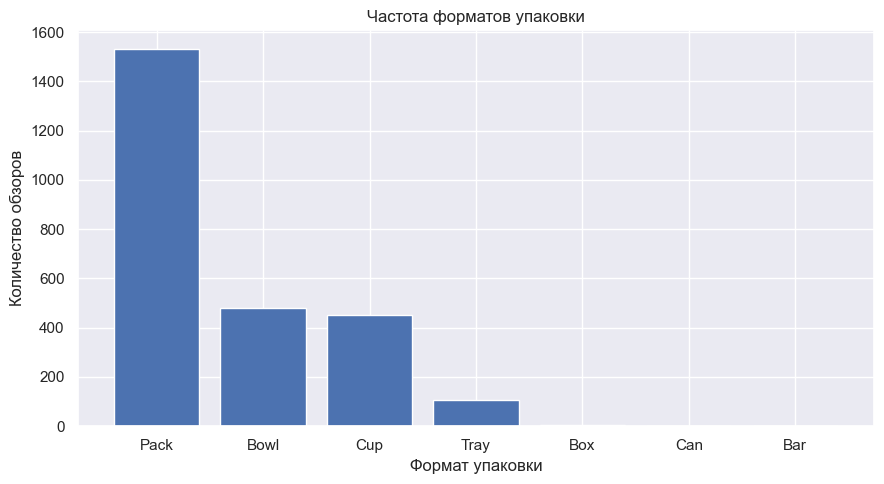

In [6]:
counts = data["Style"].value_counts().dropna()
plt.figure(figsize=(9,5)); plt.bar(counts.index.astype(str), counts.values)
plt.title("Частота форматов упаковки"); plt.xlabel("Формат упаковки"); plt.ylabel("Количество обзоров")
plt.tight_layout(); plt.savefig(OUT/"04_packaging_frequency.png", dpi=160); plt.show()

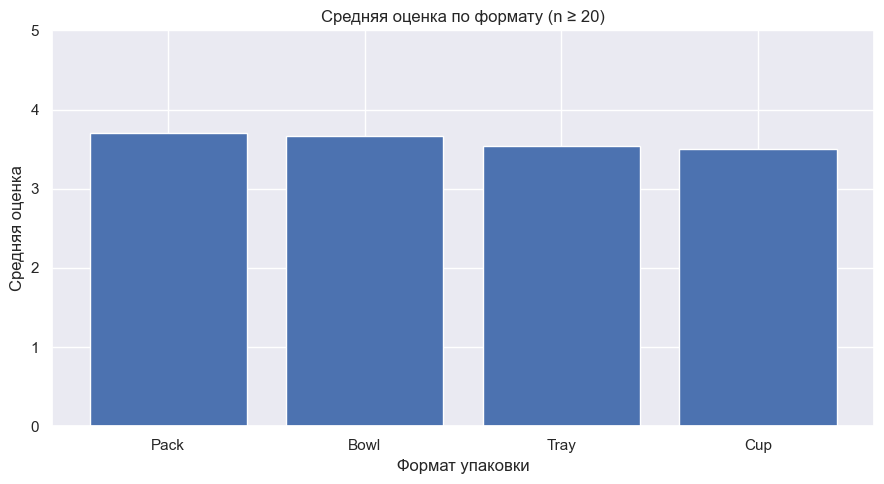

,mean,count
Style,,
Pack,3.700458,1528
Bowl,3.670686,481
Tray,3.545139,108
Cup,3.498500,450


In [7]:
stats = data.groupby("Style")["Stars"].agg(["mean","count"]).query("count >= 20").sort_values("mean", ascending=False)
plt.figure(figsize=(9,5)); plt.bar(stats.index.astype(str), stats["mean"]); plt.ylim(0,5)
plt.title("Средняя оценка по формату (n ≥ 20)"); plt.xlabel("Формат упаковки"); plt.ylabel("Средняя оценка")
plt.tight_layout(); plt.savefig(OUT/"03_rating_by_style.png", dpi=160); plt.show()
display(stats)

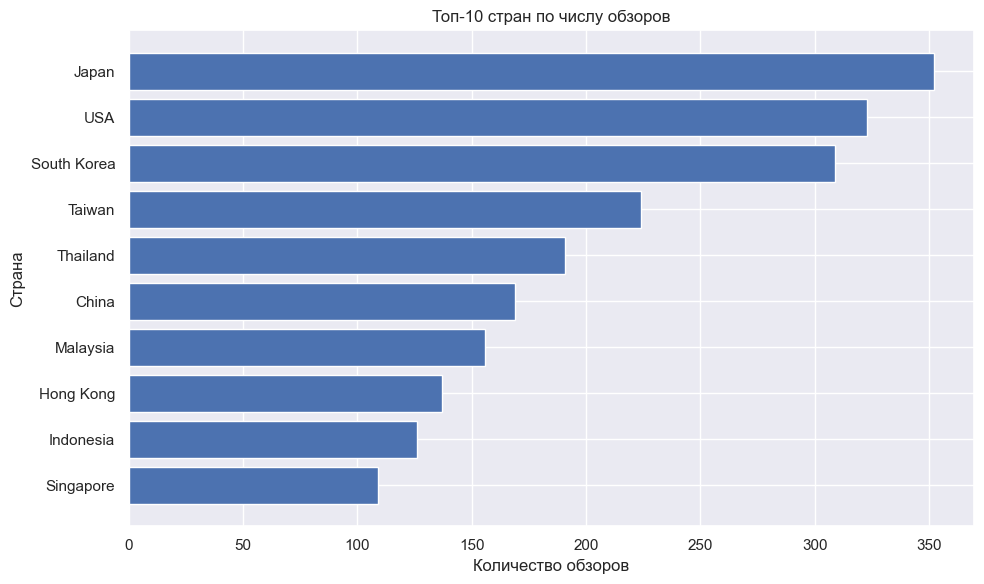

In [8]:
counts = data["Country"].value_counts().head(10)
plt.figure(figsize=(10,6)); plt.barh(counts.index[::-1].astype(str), counts.values[::-1])
plt.title("Топ-10 стран по числу обзоров"); plt.xlabel("Количество обзоров"); plt.ylabel("Страна")
plt.tight_layout(); plt.savefig(OUT/"06_country_frequency.png", dpi=160); plt.show()

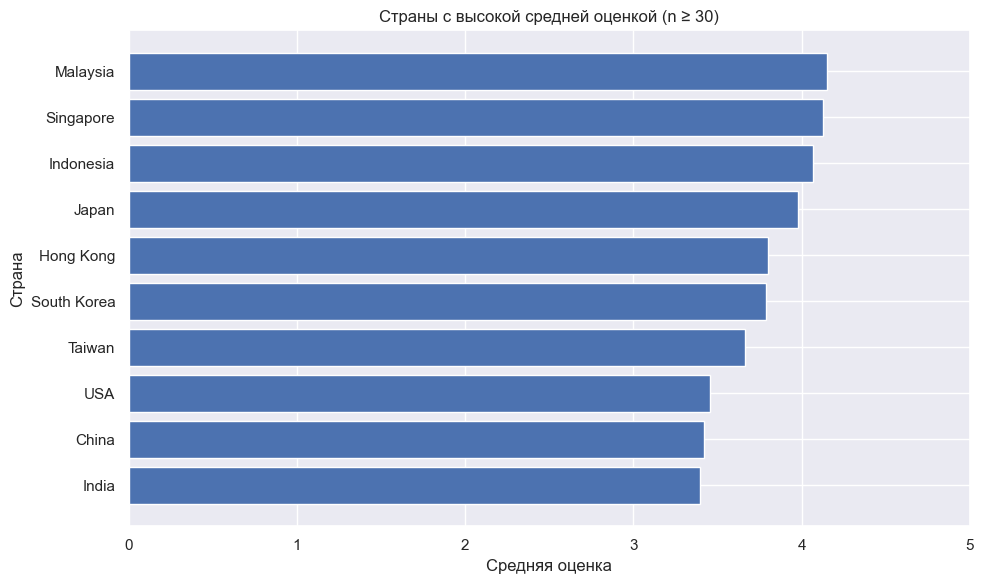

,mean,count
Country,,
Malaysia,4.154194,155
Singapore,4.126147,109
Indonesia,4.067460,126
Japan,3.981605,352
Hong Kong,3.801825,137
South Korea,3.790554,307
Taiwan,3.665402,224
USA,3.457043,323
China,3.421893,169


In [9]:
cs = data.groupby("Country")["Stars"].agg(["mean","count"]).query("count >= 30").sort_values("mean", ascending=False).head(10)
plt.figure(figsize=(10,6)); plt.barh(cs.index[::-1].astype(str), cs["mean"].values[::-1]); plt.xlim(0,5)
plt.title("Страны с высокой средней оценкой (n ≥ 30)"); plt.xlabel("Средняя оценка"); plt.ylabel("Страна")
plt.tight_layout(); plt.savefig(OUT/"07_rating_by_country.png", dpi=160); plt.show()
display(cs)

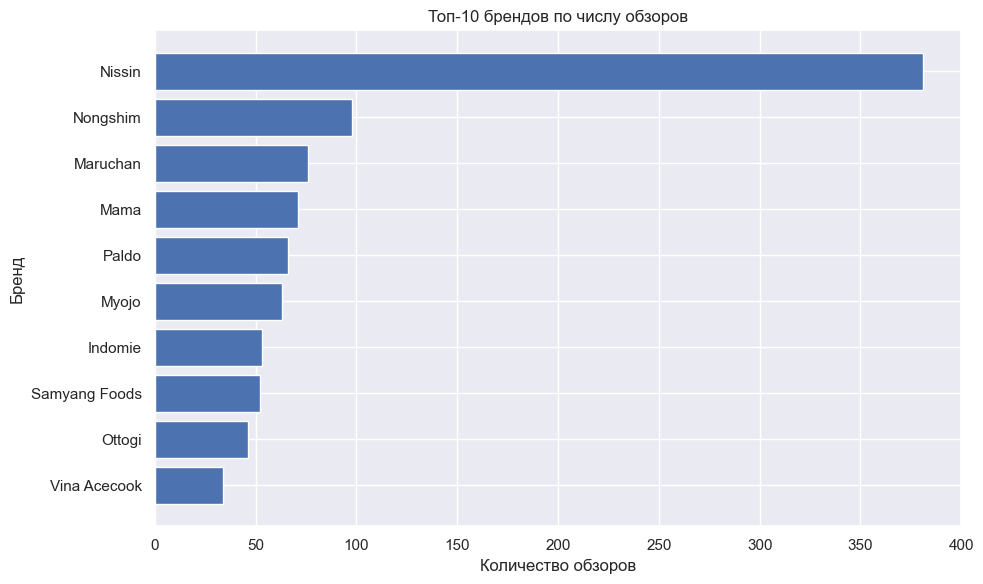

In [10]:
counts = data["Brand"].value_counts().head(10)
plt.figure(figsize=(10,6)); plt.barh(counts.index[::-1].astype(str), counts.values[::-1])
plt.title("Топ-10 брендов по числу обзоров"); plt.xlabel("Количество обзоров"); plt.ylabel("Бренд")
plt.tight_layout(); plt.savefig(OUT/"10_brand_frequency.png", dpi=160); plt.show()

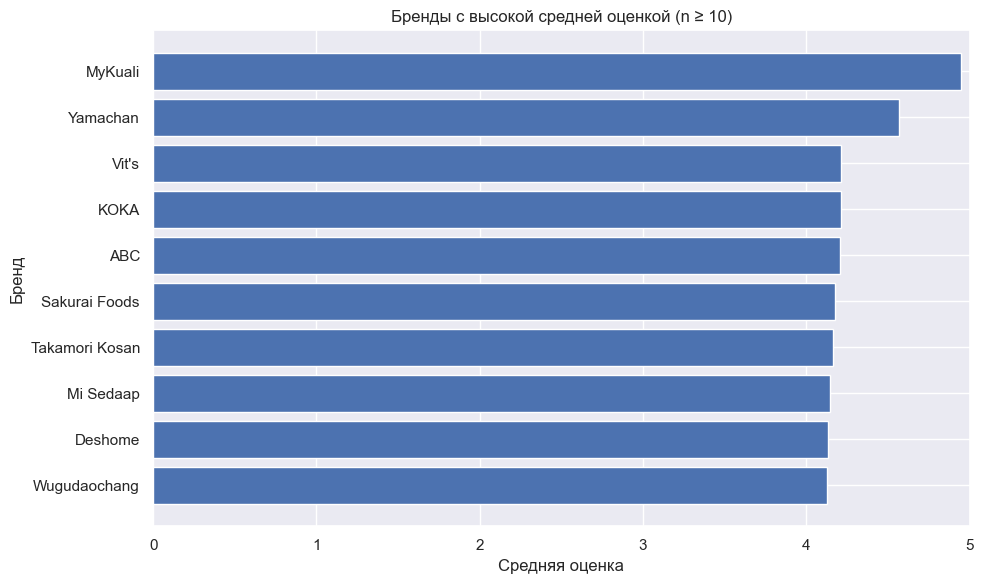

,mean,count
Brand,,
MyKuali,4.947917,24
Yamachan,4.568182,11
Vit's,4.211538,13
KOKA,4.210000,25
ABC,4.208333,12
Sakurai Foods,4.175000,10
Takamori Kosan,4.160714,14
Mi Sedaap,4.145833,12
Deshome,4.134615,13


In [11]:
bs = data.groupby("Brand")["Stars"].agg(["mean","count"]).query("count >= 10").sort_values("mean", ascending=False).head(10)
plt.figure(figsize=(10,6)); plt.barh(bs.index[::-1].astype(str), bs["mean"].values[::-1]); plt.xlim(0,5)
plt.title("Бренды с высокой средней оценкой (n ≥ 10)"); plt.xlabel("Средняя оценка"); plt.ylabel("Бренд")
plt.tight_layout(); plt.savefig(OUT/"11_rating_by_brand.png", dpi=160); plt.show()
display(bs)

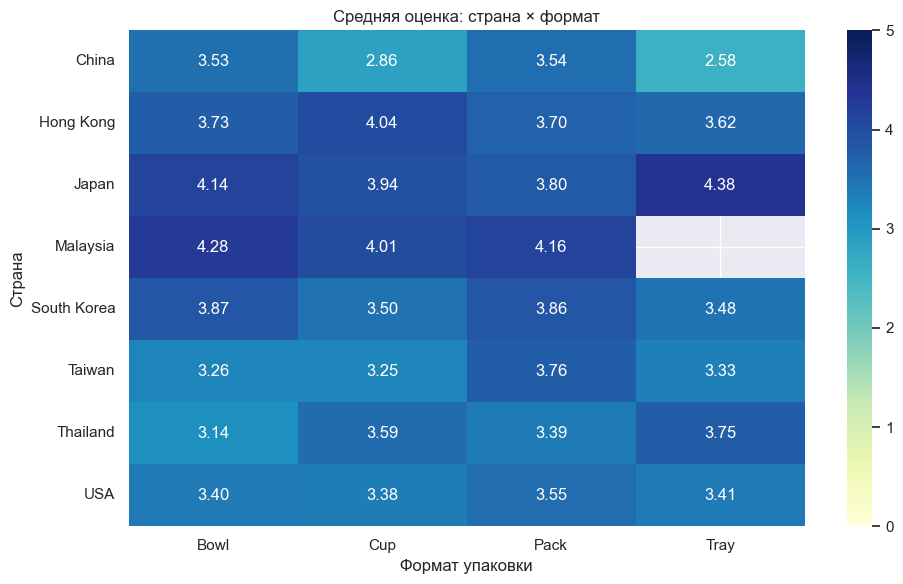

Style,Bowl,Cup,Pack,Tray
Country,,,,
China,3.527778,2.859375,3.538776,2.583333
Hong Kong,3.735000,4.039474,3.702239,3.625000
Japan,4.140278,3.940816,3.801613,4.375000
Malaysia,4.281250,4.011905,4.156452,NaN
South Korea,3.865809,3.500000,3.857459,3.479167
Taiwan,3.263514,3.250000,3.761326,3.333333
Thailand,3.142045,3.588542,3.386598,3.750000
USA,3.400000,3.376786,3.554688,3.408654


In [12]:
countries = data["Country"].value_counts().head(8).index
styles = data["Style"].value_counts().head(4).index
pivot = data[data["Country"].isin(countries) & data["Style"].isin(styles)].pivot_table(index="Country", columns="Style", values="Stars", aggfunc="mean")
plt.figure(figsize=(10,6)); sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=5)
plt.title("Средняя оценка: страна × формат"); plt.xlabel("Формат упаковки"); plt.ylabel("Страна")
plt.tight_layout(); plt.savefig(OUT/"08_country_style_heatmap.png", dpi=160); plt.show()
display(pivot)

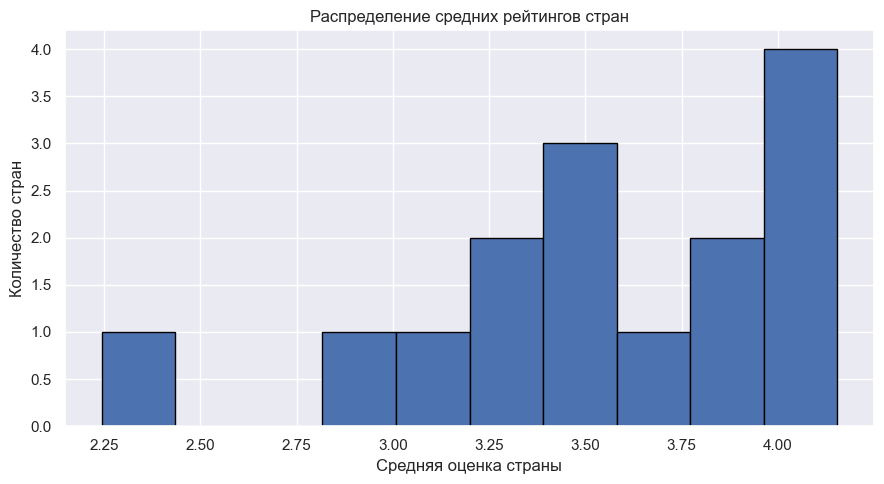

In [13]:
country_stats = (
    data.groupby("Country")["Stars"]
    .agg(["mean", "count"])
)
country_means = country_stats.loc[
    country_stats["count"] >= 30, "mean"
].dropna()
plt.figure(figsize=(9, 5))
plt.hist(country_means, bins=10, edgecolor="black")
plt.title("Распределение средних рейтингов стран")
plt.xlabel("Средняя оценка страны")
plt.ylabel("Количество стран")
plt.tight_layout()
plt.savefig(OUT/"09_country_mean_distribution.png", dpi=160)
plt.show()

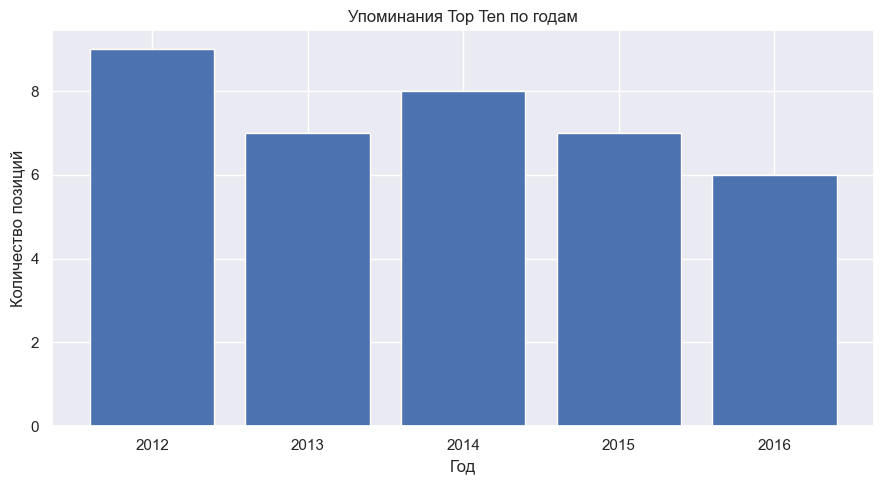

In [14]:
top = data["Top Ten"].dropna().astype(str)
years = top.str.extract(r"(\d{4})")[0].dropna().value_counts().sort_index()
plt.figure(figsize=(9,5)); plt.bar(years.index.astype(str), years.values)
plt.title("Упоминания Top Ten по годам"); plt.xlabel("Год"); plt.ylabel("Количество позиций")
plt.tight_layout(); plt.savefig(OUT/"12_top_ten_by_year.png", dpi=160); plt.show()

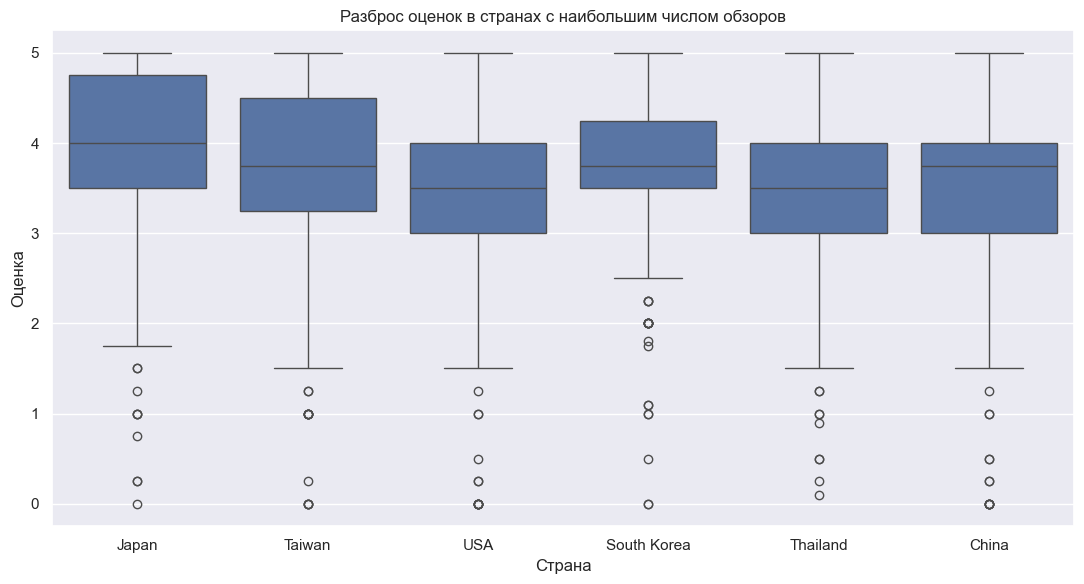

In [15]:
countries = data["Country"].value_counts().head(6).index
plt.figure(figsize=(11,6)); sns.boxplot(data=data[data["Country"].isin(countries)], x="Country", y="Stars")
plt.title("Разброс оценок в странах с наибольшим числом обзоров"); plt.xlabel("Страна"); plt.ylabel("Оценка")
plt.tight_layout(); plt.savefig(OUT/"05_rating_spread_countries.png", dpi=160); plt.show()